In [ ]:
!pip install blitz-bayesian-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 2.0 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import matplotlib.pyplot as plt
import math
import numpy as np
import torch
import pickle
import json
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
from blitz.modules import BayesianLinear
from blitz.utils import variational_estimator
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr


In [ ]:
start = -7
end = 7
n = 300
batch_size = 16

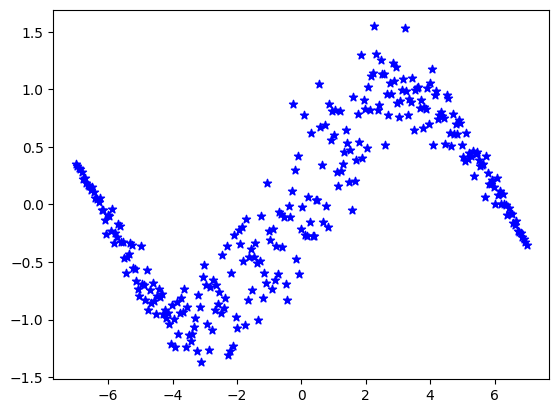

In [ ]:
def sample_dataset(start, end, n):
    np.random.seed(0)
    x = np.linspace(start, end, n)
    sample_mean = [math.sin(i/2) for i in x]

    sample_var = [abs((abs(start)+abs(end))/2 - abs(i))/16 for i in x]
    y = stats.norm(sample_mean, sample_var).rvs(random_state=0)
    return x, y

x_train, y_train = sample_dataset(start, end, n)
scatter(x_train, y_train, c="blue", marker="*")

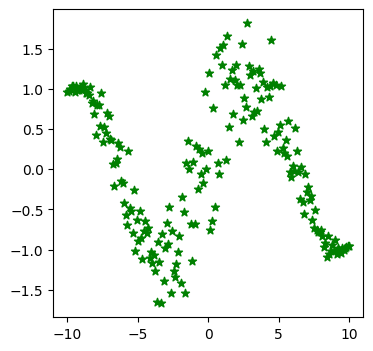

In [ ]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x_test, y_test = sample_dataset(-10, 10, 200)
scatter(x_test, y_test, c="green", marker="*")

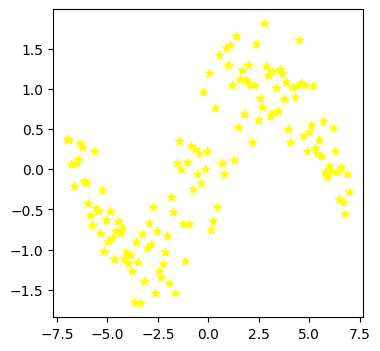

In [ ]:
#Plotting In Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask =  (x_test >= -7) &  (x_test <= 7) # Select the ranges -10 to -7 and 7 to 10
x_test_idd = x_test[mask]
y_test_idd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_idd, y_test_idd, c="yellow", marker="*")

plt.show()


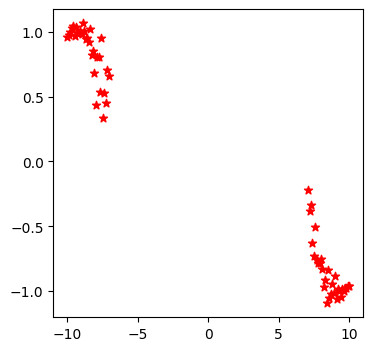

In [ ]:
#Plotting Out of Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask = (x_test >= -10) & (x_test < -7) | (x_test > 7) & (x_test <= 10) # Select the ranges -10 to -7 and 7 to 10
x_test_oodd = x_test[mask]
y_test_oodd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_oodd, y_test_oodd, c="red", marker="*")

plt.show()


In [ ]:

# Train
tensor_x = torch.Tensor(x_train).unsqueeze(1)
tensor_y = torch.Tensor(y_train).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(x_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

#Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(x_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(x_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [ ]:
class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()
        hidden_size = 60

        # We only have 1 input feature
        self.fc1 = nn.Linear(1, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.mu = nn.Linear(hidden_size, 1)
        self.var = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = torch.tanh(self.fc1(x))
        h = torch.tanh(self.fc2(h))
        mu = self.mu(h)
        # Exponential activation to enforce positive var
        var = torch.exp(self.var(h))
        return mu, var

In [ ]:

def plot_with_confidence_interval(model, tensor_x_test, tensor_y_test, x_test,y_test,color,start, end):
    sns.set(rc={'figure.figsize': (4, 4)})
    mus = []
    vars = []
    for m in model:
        mu, var = m(tensor_x_test)
        mus.append(mu)
        vars.append(var)
    # For epistemic uncertainty we calculate the std on the mus!
    means = torch.stack(mus).mean(axis=0).detach().numpy()
    stds = torch.stack(mus).std(axis=0).detach().numpy()**(1/2)
    mu = means
    sigma = stds
    # Calculate the 95% confidence interval
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma

    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')
    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []

    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_x_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()

    # Plot predictions with confidence
    sns_plot = sns.lineplot(data=df, x="x", y="y")

    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)

    # Plot test data on top
    scatter(x_test, y_test, c=color, marker="*", alpha=0.5)
    plt.show()
    return percentage_count_within_ci


In [ ]:


def train_and_evaluate_net(train_loader, test_loader, tensor_x_test, tensor_y_test,  x_test,y_test,color,num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    num_models = 5
    deep_ensemble = [SimpleNet().to(device) for i in range(num_models)]
    criterion = torch.nn.GaussianNLLLoss(eps=1e-02)
    optimizers = [optim.Adam(m.parameters(), lr=0.001) for m in deep_ensemble]
    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            losses = []
            mus = []
            vars = []
            for i, model in enumerate(deep_ensemble):
              optimizers[i].zero_grad()
              mu, var = model(x)
              loss = criterion(mu, y, var)
              loss.backward()
              optimizers[i].step()
              criterionmse_train = nn.MSELoss()
              mse_train = criterionmse_train(mu, y)
              losses.append(loss.item())
              mus.append(mu)
              vars.append(var)
            loss = sum(losses)/len(losses)
        if epoch % 10 == 0:
            all_test_losses = []
            all_mse_test = []
            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                test_losses = []
                mus = []
                vars = []
                for i, model in enumerate(deep_ensemble):
                  optimizers[i].zero_grad()
                  mu, var = model(x)
                  test_loss = criterion(mu, y, var)
                  optimizers[i].step()
                  test_losses.append(test_loss.item())
                  mus.append(mu)
                  vars.append(var)
                all_test_losses.append((sum(test_losses)/len(test_losses)))
                criterionmse_test = nn.MSELoss()
                all_mse_test.append(criterionmse_test(mu, y).item())
    test_loss = sum(all_test_losses) / len(all_test_losses)
    test_mse = sum(all_mse_test) / len(all_mse_test)
    percentage_count_within_ci=plot_with_confidence_interval(deep_ensemble,tensor_x_test, tensor_y_test,x_test,y_test,color,start, end)
    return loss, test_loss, mse_train, test_mse,deep_ensemble,percentage_count_within_ci

def Neural_Network(train_loader,test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color):
    loss, test_loss, mse_train, test_mse,deep_ensemble,percentage_count_within_ci = train_and_evaluate_net(train_loader, test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color)
    return loss, test_loss, mse_train, test_mse,deep_ensemble,percentage_count_within_ci



In [ ]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors_x":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "color":["green","red","yellow"],
  "testset_x":["x_test","x_test_oodd","x_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "x_test": x_test,
    "x_test_oodd": x_test_oodd,
    "x_test_idd": x_test_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}

# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors_x=data["test_tensors_x"]
test_tensors_y=data["test_tensors_y"]
color=data["color"]
testset_x=data["testset_x"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Number of data points within the 95% confidence interval: 114
Percentage of data points within the 95% confidence interval: 56.99999999999999


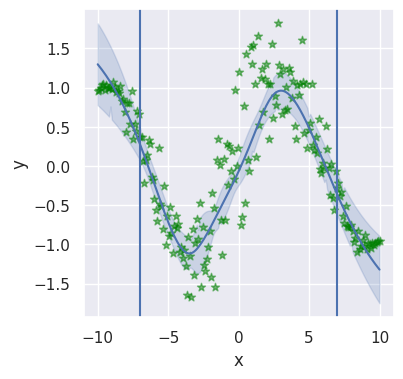

Number of data points within the 95% confidence interval: 115
Percentage of data points within the 95% confidence interval: 57.49999999999999


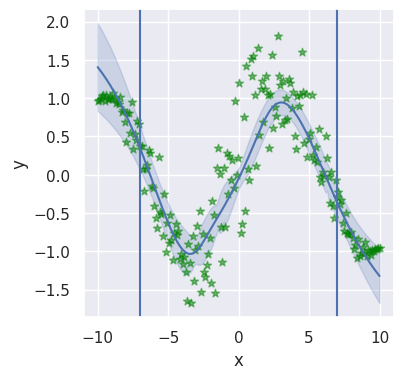

Number of data points within the 95% confidence interval: 106
Percentage of data points within the 95% confidence interval: 53.0


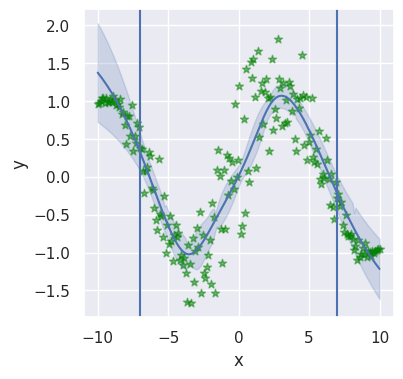

Number of data points within the 95% confidence interval: 125
Percentage of data points within the 95% confidence interval: 62.5


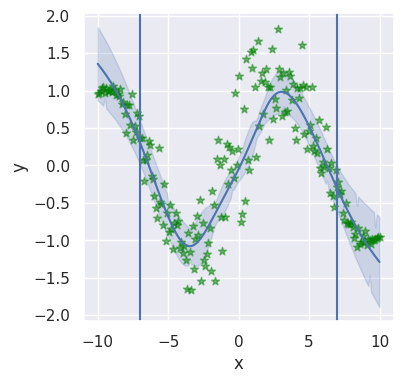

Number of data points within the 95% confidence interval: 122
Percentage of data points within the 95% confidence interval: 61.0


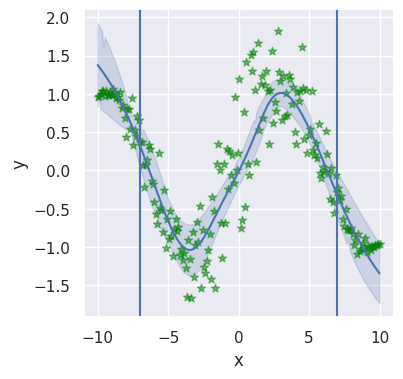

Number of data points within the 95% confidence interval: 98
Percentage of data points within the 95% confidence interval: 49.0


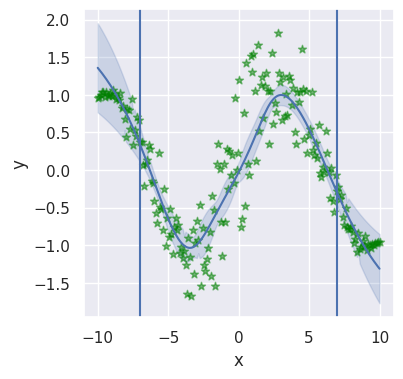

Number of data points within the 95% confidence interval: 125
Percentage of data points within the 95% confidence interval: 62.5


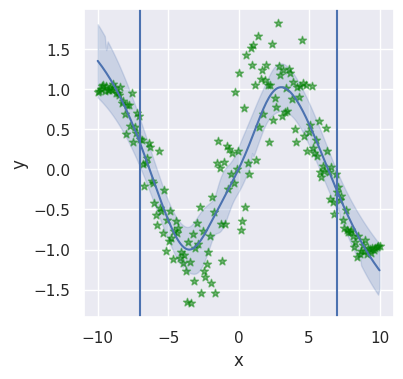

Number of data points within the 95% confidence interval: 119
Percentage of data points within the 95% confidence interval: 59.5


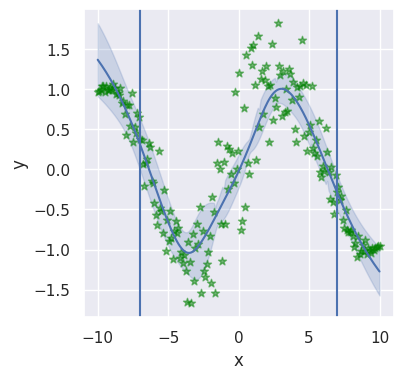

Number of data points within the 95% confidence interval: 139
Percentage of data points within the 95% confidence interval: 69.5


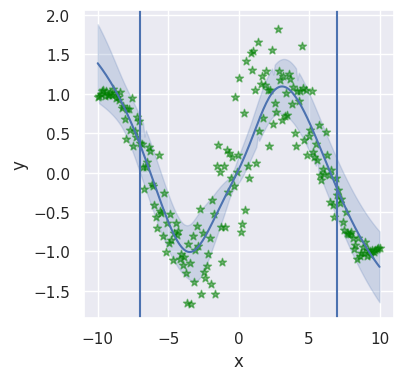

Number of data points within the 95% confidence interval: 131
Percentage of data points within the 95% confidence interval: 65.5


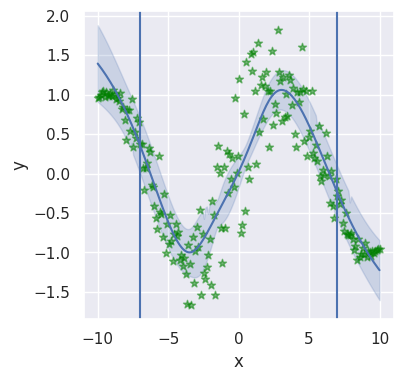

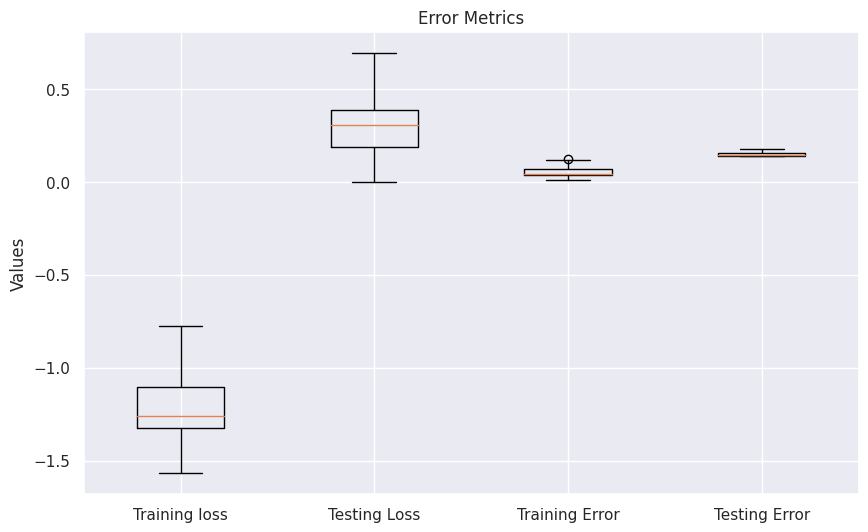

    Training Loss  Testing Loss  Mean Squared Training Error  \
1       -1.178836      0.357380                     0.042090   
2       -0.858003      0.170474                     0.125140   
3       -1.371973      0.610962                     0.052332   
4       -1.281536      0.695946                     0.046568   
5       -0.776804      0.386962                     0.118358   
6       -1.291193      0.256823                     0.033338   
7       -1.565394     -0.000039                     0.013349   
8       -1.335790      0.236151                     0.040695   
9       -1.077567      0.156780                     0.076736   
10      -1.239270      0.391719                     0.035548   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                     0.161552                                57.0  
2                     0.142090                                57.5  
3                     0.178544                                53.0  
4                  

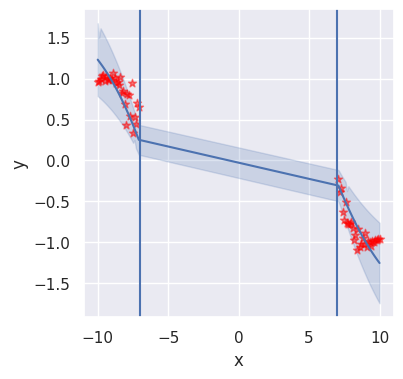

Number of data points within the 95% confidence interval: 51
Percentage of data points within the 95% confidence interval: 85.0


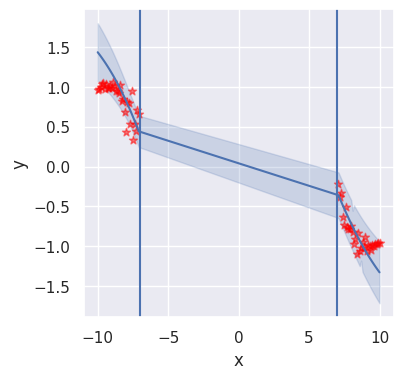

Number of data points within the 95% confidence interval: 53
Percentage of data points within the 95% confidence interval: 88.33333333333333


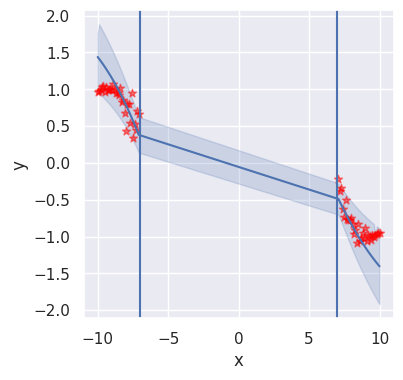

Number of data points within the 95% confidence interval: 53
Percentage of data points within the 95% confidence interval: 88.33333333333333


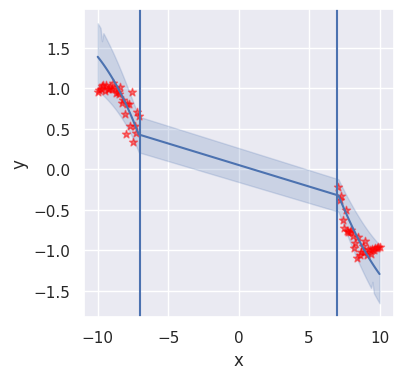

Number of data points within the 95% confidence interval: 57
Percentage of data points within the 95% confidence interval: 95.0


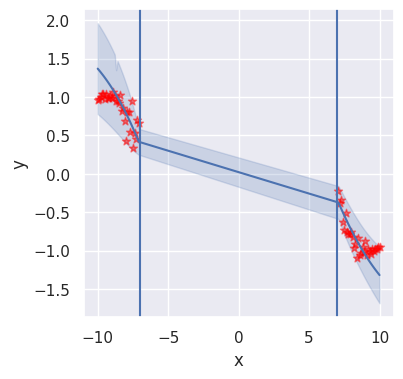

Number of data points within the 95% confidence interval: 42
Percentage of data points within the 95% confidence interval: 70.0


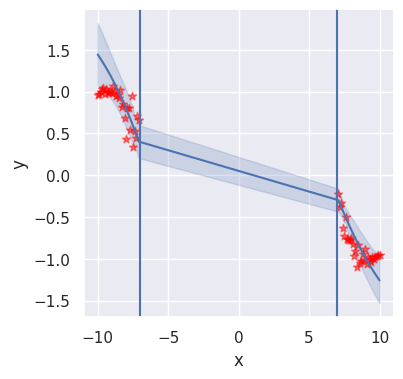

Number of data points within the 95% confidence interval: 60
Percentage of data points within the 95% confidence interval: 100.0


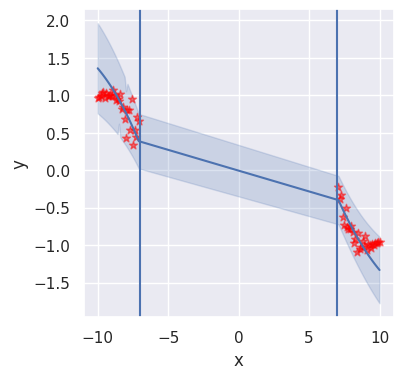

Number of data points within the 95% confidence interval: 56
Percentage of data points within the 95% confidence interval: 93.33333333333333


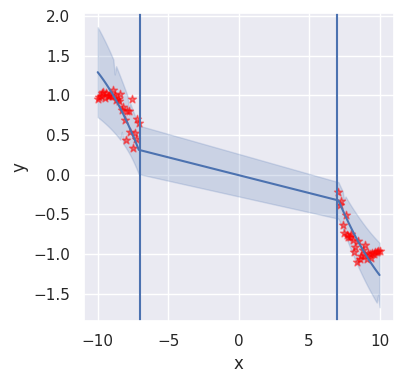

Number of data points within the 95% confidence interval: 53
Percentage of data points within the 95% confidence interval: 88.33333333333333


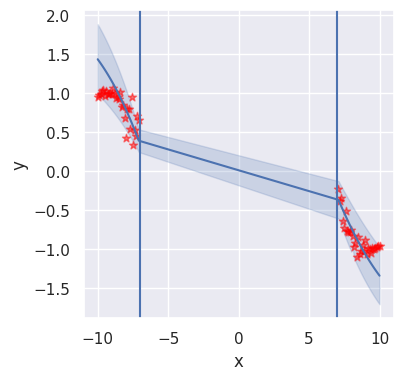

Number of data points within the 95% confidence interval: 49
Percentage of data points within the 95% confidence interval: 81.66666666666667


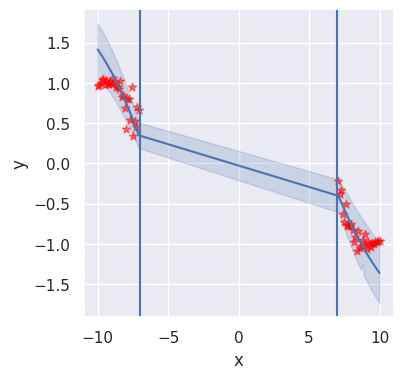

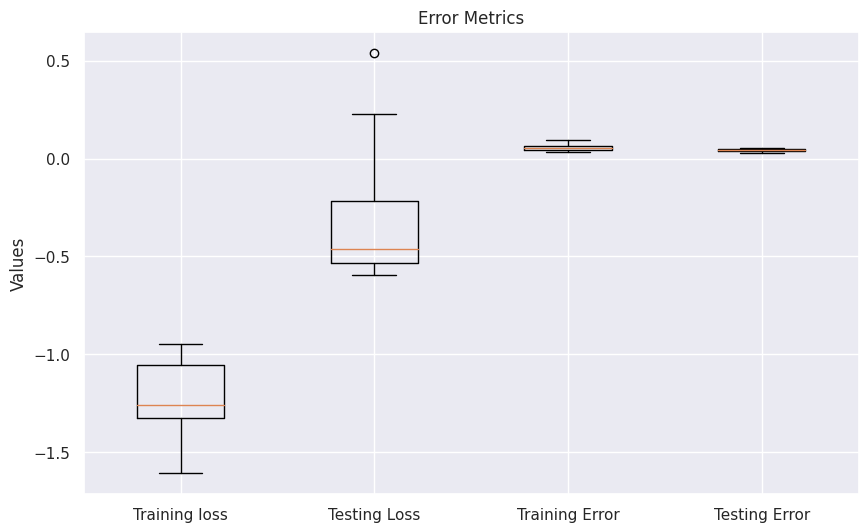

    Training Loss  Testing Loss  Mean Squared Training Error  \
1       -1.024920     -0.554558                     0.075849   
2       -1.285310      0.226445                     0.067142   
3       -1.324307     -0.327886                     0.056549   
4       -1.604183     -0.179851                     0.036606   
5       -1.326032     -0.593945                     0.044594   
6       -1.037136     -0.471368                     0.096516   
7       -0.947205     -0.588224                     0.064112   
8       -1.100065     -0.462580                     0.041595   
9       -1.228275     -0.463372                     0.050493   
10      -1.420457      0.539772                     0.033743   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                     0.038692                           91.666667  
2                     0.046037                           85.000000  
3                     0.054252                           88.333333  
4                  

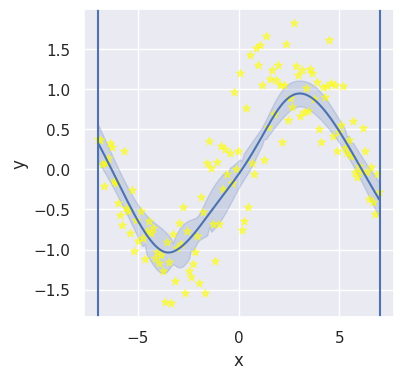

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 45.0


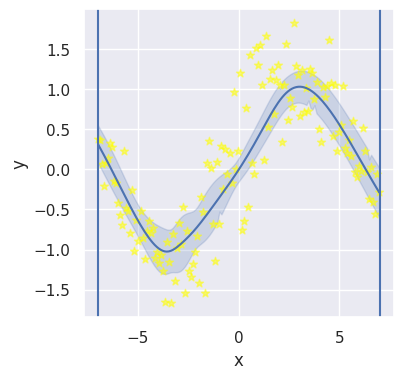

Number of data points within the 95% confidence interval: 49
Percentage of data points within the 95% confidence interval: 35.0


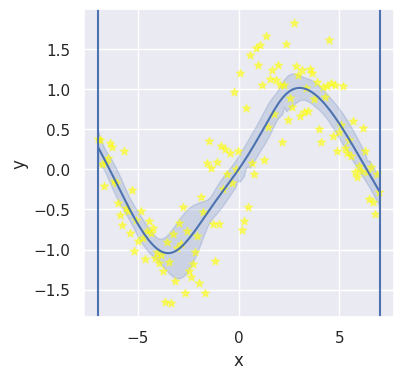

Number of data points within the 95% confidence interval: 51
Percentage of data points within the 95% confidence interval: 36.42857142857142


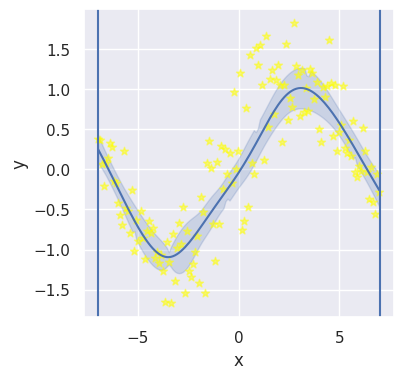

Number of data points within the 95% confidence interval: 43
Percentage of data points within the 95% confidence interval: 30.714285714285715


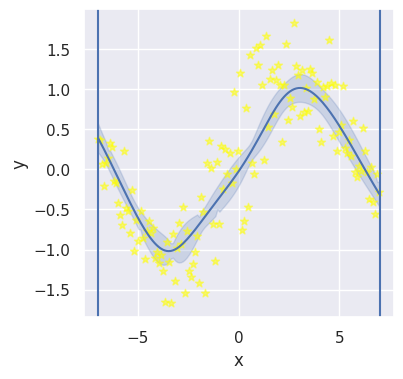

Number of data points within the 95% confidence interval: 51
Percentage of data points within the 95% confidence interval: 36.42857142857142


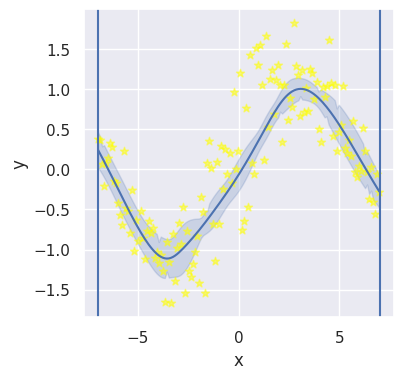

Number of data points within the 95% confidence interval: 46
Percentage of data points within the 95% confidence interval: 32.857142857142854


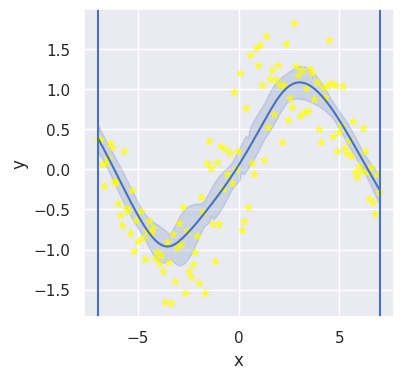

Number of data points within the 95% confidence interval: 46
Percentage of data points within the 95% confidence interval: 32.857142857142854


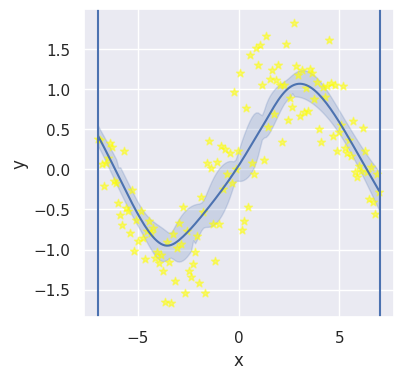

Number of data points within the 95% confidence interval: 41
Percentage of data points within the 95% confidence interval: 29.28571428571429


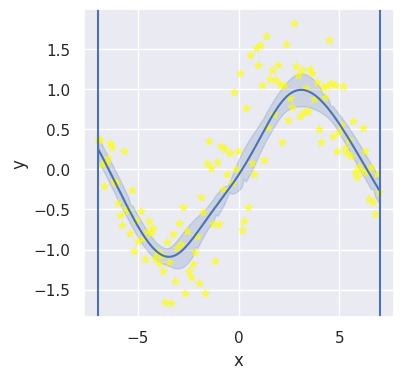

Number of data points within the 95% confidence interval: 66
Percentage of data points within the 95% confidence interval: 47.14285714285714


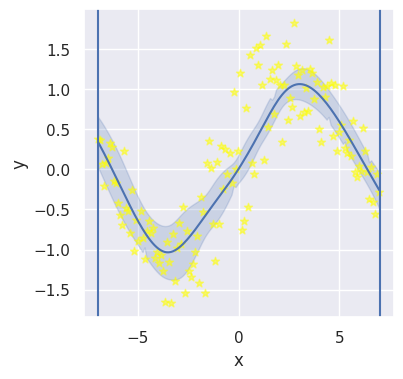

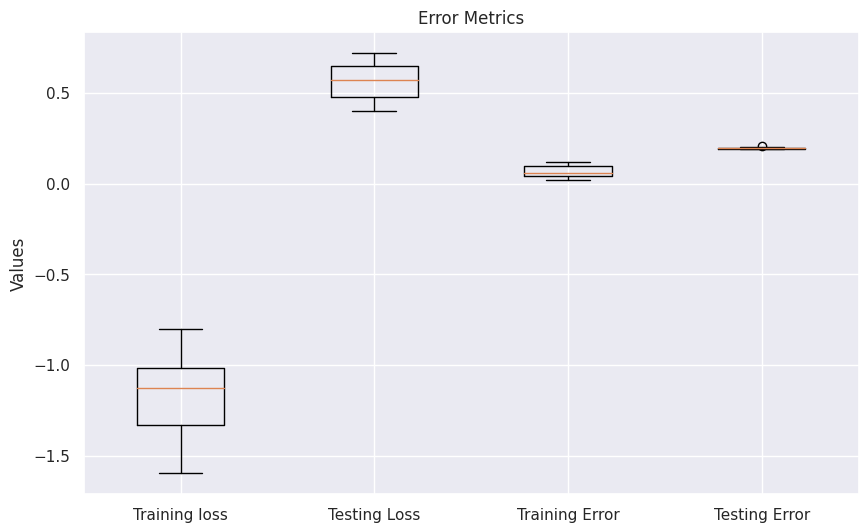

    Training Loss  Testing Loss  Mean Squared Training Error  \
1       -1.244226      0.544657                     0.053169   
2       -1.363079      0.586457                     0.041676   
3       -1.044131      0.403063                     0.104523   
4       -0.800960      0.557484                     0.121203   
5       -0.943581      0.662173                     0.103500   
6       -1.175942      0.433733                     0.052131   
7       -1.082729      0.721318                     0.066045   
8       -1.580060      0.453690                     0.019253   
9       -1.010149      0.603089                     0.068375   
10      -1.594930      0.692507                     0.025270   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                     0.192696                           36.428571  
2                     0.196222                           45.000000  
3                     0.194654                           35.000000  
4                  

In [ ]:
for tst_loader,tnsor_x_test,tnsor_y_test, col, x_test,y_test,output_dir, error_metric in zip(test_loaders,test_tensors_x,test_tensors_y,color,testset_x,testset_y,output_dirs,error_mets):
  train_losses=[]
  test_losses=[]
  errors_train=[]
  errors_test=[]
  percentages_count_within_ci=[]
  for i in range(10):
    tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci = Neural_Network(train_loader,test_loader_vars[tst_loader],tensor_x_mapping[tnsor_x_test],tensor_y_mapping[tnsor_y_test],testset_x_mapping[x_test],testset_y_mapping[y_test],col)
    error_metrics=tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)
    errors_train.append(mse_tr)
    errors_test.append(mse_test)
    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= train_losses
  test_loss_values=test_losses
  tr_errors_values= [tensor.item() for tensor in errors_train]
  test_errors_values= errors_test
  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values, tr_errors_values, test_errors_values]
  box_labels = ['Training loss', 'Testing Loss', 'Training Error', 'Testing Error']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'denn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_mse_train = np.mean(tr_errors_values)
  std_dev_mse_train = np.std(tr_errors_values)

  mean_mse_test = np.mean(test_errors_values)
  std_dev_mse_test = np.std(test_errors_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    'Mean Squared Training Error': tr_errors_values,
    'Mean Squared Testing Error': test_errors_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }

  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss', 'Mean Squared Training Error','Mean Squared Testing Error','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'denn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of MSE Training of 10 runs ',mean_mse_train)
  print('Standard Deviation of MSE Training of 10 runs ' , std_dev_mse_train)

  print('Mean of MSE Testing of 10 runs ',mean_mse_test )
  print('Standard Deviation of MSE Testing of 10 runs ', std_dev_mse_test)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'denn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of MSE Training of 10 runs: {}\n'.format(mean_mse_train))
    file.write('Standard Deviation of MSE Training of 10 runs: {}\n\n'.format(std_dev_mse_train))

    file.write('Mean of MSE Testing of 10 runs: {}\n'.format(mean_mse_test))
    file.write('Standard Deviation of MSE Testing of 10 runs: {}\n\n'.format(std_dev_mse_test))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
